--BUSINESS UNDERSTANDING

1. import libraries
2. import dataset
3. Data Understanding

-- Assumption Tests -> Linearity / Normalization / multi-colinearity / Auto-regression(time)

-- (excluding - Homoscadesticity, Zero Residual Mean error)

### 1. Import Libraries

In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from matplotlib import pyplot as plt

### 2. Import Dataset

In [5]:
claimant_data = pd.read_csv(filepath_or_buffer='claimants.csv')
claimant_data

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...,...,...
1335,34100,1,0.0,1.0,0.0,NaN,0.576
1336,34110,0,1.0,1.0,0.0,46.0,3.705
1337,34113,1,1.0,1.0,0.0,39.0,0.099
1338,34145,0,1.0,0.0,0.0,8.0,3.177


Attorney is the output - the rest is input

### 3. Data Understanding

In [6]:
claimant_data.shape

(1340, 7)

In [7]:
claimant_data.dtypes

CASENUM       int64
ATTORNEY      int64
CLMSEX      float64
CLMINSUR    float64
SEATBELT    float64
CLMAGE      float64
LOSS        float64
dtype: object

In [8]:
claimant_data.isnull().sum()

CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64

Need to Drop - And Inform CLIENT

In [9]:
claimant_data.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
1335    False
1336    False
1337    False
1338    False
1339    False
Length: 1340, dtype: bool

In [10]:
claimant_data.describe()

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
count,1340.000000,1340.000000,1328.000000,1299.000000,1292.000000,1151.000000,1340.000000
mean,11202.001493,0.488806,0.558735,0.907621,0.017028,28.414422,3.806307
std,9512.750796,0.500061,0.496725,0.289671,0.129425,20.304451,10.636903
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4177.000000,0.000000,0.000000,1.000000,0.000000,9.000000,0.400000
50%,8756.500000,0.000000,1.000000,1.000000,0.000000,30.000000,1.069500
75%,15702.500000,1.000000,1.000000,1.000000,0.000000,43.000000,3.781500
max,34153.000000,1.000000,1.000000,1.000000,1.000000,95.000000,173.604000


### Assumtion Tests

### Test 1 : Linearity Test

### 4. Data Preparation

#### 4.1 Data Cleaning

In [11]:
claimant_data.dropna(inplace=True) # By default axis is 0 , remove indexes(rows/records) with NA/null values

In [12]:
claimant_data

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,5,0,0.0,1.0,0.0,50.0,34.940
1,3,1,1.0,0.0,0.0,18.0,0.891
2,66,1,0.0,1.0,0.0,5.0,0.330
3,70,0,0.0,1.0,1.0,31.0,0.037
4,96,1,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...,...,...
1334,34104,1,1.0,1.0,0.0,16.0,0.060
1336,34110,0,1.0,1.0,0.0,46.0,3.705
1337,34113,1,1.0,1.0,0.0,39.0,0.099
1338,34145,0,1.0,0.0,0.0,8.0,3.177


In [13]:
claimant_data.isna().sum()

CASENUM     0
ATTORNEY    0
CLMSEX      0
CLMINSUR    0
SEATBELT    0
CLMAGE      0
LOSS        0
dtype: int64

#### 4.2 Seperate input & output

we also need to use common sense when cleaning the data (during data cleaning)
- dropping the CASENUM - bacause it is just an ID
- ATTORNEY is the output - Y

In [14]:
X = claimant_data.drop(columns=['CASENUM','ATTORNEY'], axis = 1)
X

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,34.940
1,1.0,0.0,0.0,18.0,0.891
2,0.0,1.0,0.0,5.0,0.330
3,0.0,1.0,1.0,31.0,0.037
4,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...
1334,1.0,1.0,0.0,16.0,0.060
1336,1.0,1.0,0.0,46.0,3.705
1337,1.0,1.0,0.0,39.0,0.099
1338,1.0,0.0,0.0,8.0,3.177


In [15]:
y = claimant_data['ATTORNEY']
y

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

### 5. Model Building

In [ ]:
# Train / Test Split

In [34]:
X_test, X_train, y_test, y_train = train_test_split(X, y, test_size=0.8, shuffle=True, random_state=32)
(X_test, X_train, y_test, y_train)

(      CLMSEX  CLMINSUR  SEATBELT  CLMAGE    LOSS
 430      0.0       0.0       0.0    15.0   0.984
 632      1.0       1.0       0.0     1.0   3.404
 1188     1.0       1.0       0.0    44.0  13.000
 221      0.0       1.0       0.0    44.0   0.035
 193      1.0       1.0       0.0    49.0   3.968
 ...      ...       ...       ...     ...     ...
 625      1.0       1.0       0.0    71.0   8.708
 305      0.0       1.0       0.0    33.0   0.886
 107      1.0       0.0       0.0    10.0   3.975
 1091     0.0       0.0       0.0    47.0   6.070
 895      0.0       1.0       0.0    16.0   1.800
 
 [219 rows x 5 columns],
       CLMSEX  CLMINSUR  SEATBELT  CLMAGE   LOSS
 1035     0.0       1.0       0.0    10.0  0.663
 1255     0.0       1.0       0.0    48.0  0.455
 347      1.0       1.0       0.0    56.0  3.009
 121      1.0       1.0       0.0     9.0  5.813
 511      1.0       1.0       0.0     8.0  3.086
 ...      ...       ...       ...     ...    ...
 589      1.0       1.0       

In [28]:
logistic_model = LogisticRegression()

### 6. Model Training

In [36]:
logistic_model.fit(X_train,y_train)

LogisticRegression()

### 7. Model Testing

In [37]:
y_pred_train = logistic_model.predict(X_train)

y_pred_test = logistic_model.predict(X_test)

y_pred_test,y_pred_train


(array([0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0,
        1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0,
        0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0,
        0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1,
        0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1,
        0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0,
        1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1,
        1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1,
        1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
       dtype=int64),
 array([1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1,
        1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1,
        1, 1, 1, 0,

In [ ]:
# claimant_data['predicted_Output'] = logistic_model.predict(X)
# claimant_data

,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS,predicted_Output
0,5,0,0.0,1.0,0.0,50.0,34.940,0
1,3,1,1.0,0.0,0.0,18.0,0.891,1
2,66,1,0.0,1.0,0.0,5.0,0.330,1
3,70,0,0.0,1.0,1.0,31.0,0.037,0
4,96,1,0.0,1.0,0.0,30.0,0.038,1
...,...,...,...,...,...,...,...,...
1334,34104,1,1.0,1.0,0.0,16.0,0.060,1
1336,34110,0,1.0,1.0,0.0,46.0,3.705,0
1337,34113,1,1.0,1.0,0.0,39.0,0.099,1
1338,34145,0,1.0,0.0,0.0,8.0,3.177,0


###  8. Model Evaluation

In [ ]:
# from sklearn.metrics import accuracy_score
# Some metric are for CLASSIFICATIONs & some are for REGRESSION (Take Note !!)

In [48]:
accuracy_score(y_true=claimant_data['ATTORNEY'], y_pred=claimant_data['predicted_Output'])

0.708029197080292

#### Model Evaluation - after Chapter 5 - Evaluation Metrics

In [39]:
# Evaluation metrics for Classification models

from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix, f1_score

##### Training Data - Evaluation

In [41]:
# Precision / Recall - and the overall Report

print(classification_report(y_train, y_pred_train))

              precision    recall  f1-score   support

           0       0.76      0.63      0.69       446
           1       0.67      0.80      0.73       431

    accuracy                           0.71       877
   macro avg       0.72      0.71      0.71       877
weighted avg       0.72      0.71      0.71       877



In [53]:
X_test.shape

(219, 5)

In [ ]:
# Just checking the probabilties for (0 & 1) - each prediction
# to check how the threshold works - default threshold is 0.5
logistic_model.predict_proba(X_test)[:10] , y_pred_test[:10]

(array([[0.55191886, 0.44808114],
        [0.61421211, 0.38578789],
        [0.98465183, 0.01534817],
        [0.31999423, 0.68000577],
        [0.61943292, 0.38056708],
        [0.59185273, 0.40814727],
        [0.47445607, 0.52554393],
        [0.31790897, 0.68209103],
        [0.87346861, 0.12653139],
        [0.28609272, 0.71390728]]),
 array([0, 0, 0, 1, 0, 0, 1, 1, 0, 1], dtype=int64))

In [66]:
# 4. Calculate the ROC AUC score
auc_score = roc_auc_score(y_train, y_pred_train)
print(f"ROC AUC Score: {auc_score:.4f}")

ROC AUC Score: 0.7130


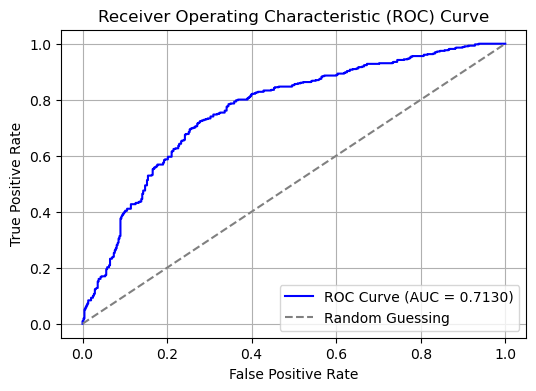

In [ ]:
# 5. Compute False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_train, logistic_model.predict_proba(X_train)[:,1])

# 6. Plot the ROC curve
plt.figure(figsize=(6, 4))
plt.plot(
    fpr, tpr, color="blue", label=f"ROC Curve (AUC = {auc_score:.4f})"
)
plt.plot(
    [0, 1], [0, 1], color="gray", linestyle="--", label="Random Guessing"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


## IMPORTANT NOTES FOR ROC AUC

# - ROC graph is basically testing all the thresholds range and possible TPR / FPR
# - must use .predict_proba(X_train)[:,1] for y_score, because we need the probbabilities, so ROC function can test with various thresholds
# - [:,1] because only need 1d array - and we are taking the probability of getting POSITIVE '1'
# - the ROC must look like a curve with realistic data

# - AUC (area under curve) - tells how the model can seperate POSITIVE (1) & NEGATIVE (0) well, overall

##### Testing Data - Evaluation

In [78]:
# Precision / Recall - and the overall Report

print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.75      0.67      0.71       132
           1       0.57      0.67      0.61        87

    accuracy                           0.67       219
   macro avg       0.66      0.67      0.66       219
weighted avg       0.68      0.67      0.67       219



In [79]:
# 4. Calculate the ROC AUC score
auc_score = roc_auc_score(y_test, y_pred_test)
print(f"ROC AUC Score: {auc_score:.4f}")

ROC AUC Score: 0.6667


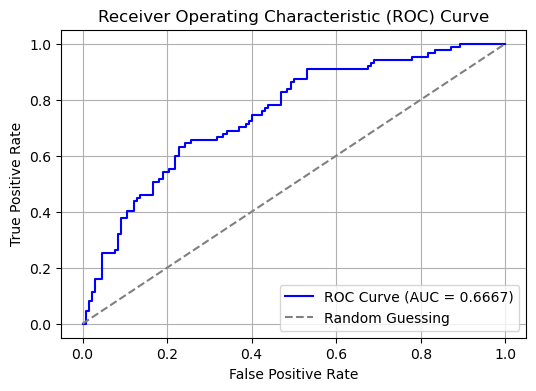

In [80]:
# 5. Compute False Positive Rate (FPR) and True Positive Rate (TPR)
fpr, tpr, thresholds = roc_curve(y_test, logistic_model.predict_proba(X_test)[:,1])

# 6. Plot the ROC curve
plt.figure(figsize=(6, 4))
plt.plot(
    fpr, tpr, color="blue", label=f"ROC Curve (AUC = {auc_score:.4f})"
)
plt.plot(
    [0, 1], [0, 1], color="gray", linestyle="--", label="Random Guessing"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


## IMPORTANT NOTES FOR ROC AUC

# - ROC graph is basically testing all the thresholds range and possible TPR / FPR
# - must use .predict_proba(X_train)[:,1] for y_score, because we need the probbabilities, so ROC function can test with various thresholds
# - [:,1] because only need 1d array - and we are taking the probability of getting POSITIVE '1'
# - the ROC must look like a curve with realistic data

# - AUC (area under curve) - tells how the model can seperate POSITIVE (1) & NEGATIVE (0) well, overall


### 9. Model Deployment

In [49]:
from pickle import dump , load

In [51]:
dump(obj=logistic_model, file=open(file='claimants.pkl', mode='wb'))